# Praktikum 3 Data Mining - Association Learning

|Nama|NRP|
|-|-|
|Vincent Valentino|5054251016|

## Import Library

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import openpyxl
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

## Data Exploration

In [27]:
retail = pd.read_excel('Online Retail.xlsx')
display(retail.shape)
display(retail.head())

(541909, 8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
retail.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900,4070,4223,NaN,23260,NaN,NaN,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,10/31/11 14:41,NaN,NaN,United Kingdom
freq,1114,2313,2369,NaN,1114,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,NaN,4.611114,15287.690570,NaN
std,NaN,NaN,NaN,218.081158,NaN,96.759853,1713.600303,NaN
min,NaN,NaN,NaN,-80995.000000,NaN,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,NaN,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,NaN,4.130000,16791.000000,NaN


In [4]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 66.2 MB


In [5]:
print(retail.duplicated().sum())
retail.isna().sum()

5268


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## Pre-processing

In [6]:
cleaned = retail[['InvoiceNo', 'Description', 'Quantity']].copy()

rows_before = len(cleaned)
invoices_before = cleaned['InvoiceNo'].nunique()

print('Sebelum Cleaning')
print(f'Jumlah baris   : {rows_before}')
print(f'Jumlah invoice : {invoices_before}')

Sebelum Cleaning
Jumlah baris   : 541909
Jumlah invoice : 25900


In [7]:
cleaned = cleaned.drop_duplicates()

In [8]:
cleaned = cleaned.dropna(subset='Description')

In [9]:
cleaned = cleaned.drop(cleaned[cleaned['InvoiceNo'].str.startswith('C')].index)

In [10]:
cleaned = cleaned.dropna()
cleaned = cleaned[cleaned['Quantity'] > 0]

In [11]:
rows_after = len(cleaned)
invoices_after = cleaned['InvoiceNo'].nunique()

print('Setelah Cleaning')
print(f'Jumlah baris   : {rows_after}')
print(f'Jumlah invoice : {invoices_after}')

Setelah Cleaning
Jumlah baris   : 525259
Jumlah invoice : 20136


In [12]:
cleaned.isna().sum()

InvoiceNo      0
Description    0
Quantity       0
dtype: int64

In [13]:
transactions = cleaned.groupby("InvoiceNo")["Description"].apply(list).tolist()
transactions[:5]

[['WHITE HANGING HEART T-LIGHT HOLDER',
  'WHITE METAL LANTERN',
  'CREAM CUPID HEARTS COAT HANGER',
  'KNITTED UNION FLAG HOT WATER BOTTLE',
  'RED WOOLLY HOTTIE WHITE HEART.',
  'SET 7 BABUSHKA NESTING BOXES',
  'GLASS STAR FROSTED T-LIGHT HOLDER'],
 ['HAND WARMER UNION JACK', 'HAND WARMER RED POLKA DOT'],
 ['ASSORTED COLOUR BIRD ORNAMENT',
  "POPPY'S PLAYHOUSE BEDROOM ",
  "POPPY'S PLAYHOUSE KITCHEN",
  'FELTCRAFT PRINCESS CHARLOTTE DOLL',
  'IVORY KNITTED MUG COSY ',
  'BOX OF 6 ASSORTED COLOUR TEASPOONS',
  'BOX OF VINTAGE JIGSAW BLOCKS ',
  'BOX OF VINTAGE ALPHABET BLOCKS',
  'HOME BUILDING BLOCK WORD',
  'LOVE BUILDING BLOCK WORD',
  'RECIPE BOX WITH METAL HEART',
  'DOORMAT NEW ENGLAND'],
 ['JAM MAKING SET WITH JARS',
  'RED COAT RACK PARIS FASHION',
  'YELLOW COAT RACK PARIS FASHION',
  'BLUE COAT RACK PARIS FASHION'],
 ['BATH BUILDING BLOCK WORD']]

In [14]:
te = TransactionEncoder()
basket = pd.DataFrame(
    te.fit(transactions).transform(transactions),
    columns=te.columns_
)

## Association Learning

In [15]:
frequent_itemsets = apriori(
    basket,
    min_support=0.01,
    use_colnames=True,
    low_memory = True
).sort_values('support', ascending=False)

frequent_itemsets = frequent_itemsets.sort_values('support',ascending=False)

print('Jumlah frequent itemsets:', len(frequent_itemsets))

frequent_itemsets.head(10)

Jumlah frequent itemsets: 1854


,support,itemsets
771,0.112237,frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
341,0.103894,frozenset({JUMBO BAG RED RETROSPOT})
550,0.098778,frozenset({REGENCY CAKESTAND 3 TIER})
458,0.083731,frozenset({PARTY BUNTING})
381,0.077672,frozenset({LUNCH BAG RED RETROSPOT})
48,0.072259,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
619,0.068782,frozenset({SET OF 3 CAKE TINS PANTRY DESIGN })
437,0.065554,frozenset({PACK OF 72 RETROSPOT CAKE CASES})
373,0.063220,frozenset({LUNCH BAG BLACK SKULL.})
411,0.062028,frozenset({NATURAL SLATE HEART CHALKBOARD })


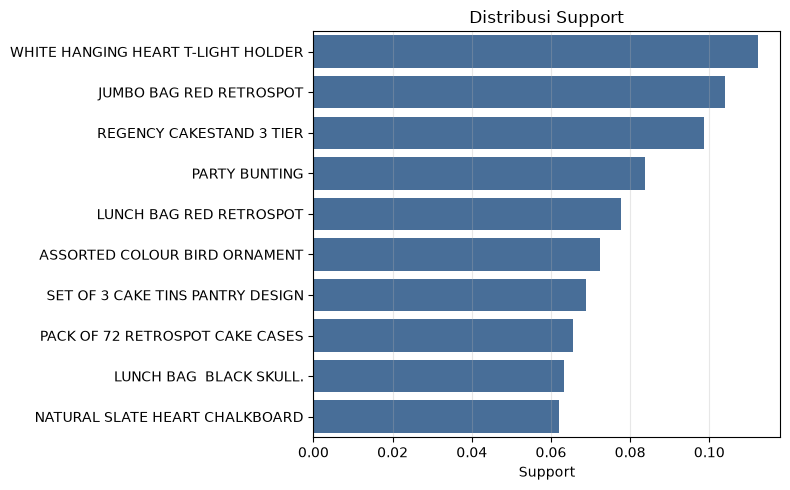

In [23]:
single = frequent_itemsets[frequent_itemsets['itemsets'].apply(len) == 1].head(10).copy()
single['produk'] = single['itemsets'].apply(lambda s: list(s)[0].strip())

plt.figure(figsize=(8, 5))
sb.barplot(data=single, x='support', y='produk', color='#3b6ea5')
plt.xlabel('Support')
plt.ylabel('')
plt.grid(alpha=0.3, axis='x')
plt.title('Distribusi Support')
plt.tight_layout()
plt.savefig('top.png', dpi=200)
plt.show()

In [18]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.5
)

result = rules[
    [
        'antecedents',
        'consequents',
        'support',
        'confidence',
        'lift'
    ]
].copy()

result = result.sort_values('lift', ascending=False)

result.head(10)

,antecedents,consequents,support,confidence,lift
824,frozenset({HERB MARKER THYME}),"frozenset({HERB MARKER PARSLEY, HERB MARKER RO...",0.010081,0.856540,80.219959
821,"frozenset({HERB MARKER PARSLEY, HERB MARKER RO...",frozenset({HERB MARKER THYME}),0.010081,0.944186,80.219959
825,frozenset({HERB MARKER ROSEMARY}),"frozenset({HERB MARKER PARSLEY, HERB MARKER TH...",0.010081,0.845833,79.961033
820,"frozenset({HERB MARKER PARSLEY, HERB MARKER TH...",frozenset({HERB MARKER ROSEMARY}),0.010081,0.953052,79.961033
600,frozenset({HERB MARKER ROSEMARY}),frozenset({HERB MARKER THYME}),0.010975,0.920833,78.235865
599,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER ROSEMARY}),0.010975,0.932489,78.235865
823,frozenset({HERB MARKER PARSLEY}),"frozenset({HERB MARKER THYME, HERB MARKER ROSE...",0.010081,0.852941,77.714134
822,"frozenset({HERB MARKER THYME, HERB MARKER ROSE...",frozenset({HERB MARKER PARSLEY}),0.010081,0.918552,77.714134
676,frozenset({HERB MARKER PARSLEY}),frozenset({HERB MARKER THYME}),0.010578,0.894958,76.037443
677,frozenset({HERB MARKER THYME}),frozenset({HERB MARKER PARSLEY}),0.010578,0.898734,76.037443


In [ ]:
view = result.copy()
view['antecedents'] = view['antecedents'].apply(lambda s: ' + '.join(sorted(i.strip() for i in s)))
view['consequents'] = view['consequents'].apply(lambda s: ' + '.join(sorted(i.strip() for i in s)))
cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift']

# Top 3 in Lift
display(view.sort_values(by='lift', ascending=False).head(3))

# Top 3 without Herb Marker
no_herb = view[~(view['antecedents'].str.contains('HERB MARKER') |
                 view['consequents'].str.contains('HERB MARKER'))]
display(no_herb.sort_values('lift', ascending=False)[cols].head(10))

# Top 3 in Support
display(view.sort_values('support', ascending=False)[cols].head(10))

# Top 3 in Confidence
display(view.sort_values('confidence', ascending=False)[cols].head(10))

,antecedents,consequents,support,confidence,lift
824,HERB MARKER THYME,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,0.010081,0.856540,80.219959
821,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010081,0.944186,80.219959
825,HERB MARKER ROSEMARY,HERB MARKER PARSLEY + HERB MARKER THYME,0.010081,0.845833,79.961033


,antecedents,consequents,support,confidence,lift
375,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,0.012664,0.836066,52.774346
374,REGENCY TEA PLATE GREEN + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE PINK,0.012664,0.799373,52.774346
373,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.012664,0.947955,50.099816
376,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,0.012664,0.669291,50.099816
258,REGENCY TEA PLATE GREEN,REGENCY TEA PLATE PINK,0.013806,0.729659,48.171834
257,REGENCY TEA PLATE PINK,REGENCY TEA PLATE GREEN,0.013806,0.911475,48.171834
608,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.010876,0.686520,47.180117
609,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.010876,0.747440,47.180117
424,REGENCY SUGAR BOWL GREEN,REGENCY MILK JUG PINK,0.012068,0.754658,46.187846
423,REGENCY MILK JUG PINK,REGENCY SUGAR BOWL GREEN,0.012068,0.738602,46.187846


,antecedents,consequents,support,confidence,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.040971,0.677340,6.519558
2,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.038141,0.720450,14.292598
1,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.038141,0.756650,14.292598
3,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.035956,0.611486,5.885704
4,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.033770,0.578723,5.570351
5,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT,0.031834,0.503535,6.482852
7,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.031784,0.608944,12.511932
6,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.031784,0.653061,12.511932
9,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.031436,0.623645,16.393893
8,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.031436,0.826371,16.393893


,antecedents,consequents,support,confidence,lift
715,JAM MAKING SET PRINTED + SUKI SHOULDER BAG,DOTCOM POSTAGE,0.010379,0.958716,27.266522
820,HERB MARKER PARSLEY + HERB MARKER THYME,HERB MARKER ROSEMARY,0.010081,0.953052,79.961033
373,REGENCY TEA PLATE PINK + REGENCY TEA PLATE ROSES,REGENCY TEA PLATE GREEN,0.012664,0.947955,50.099816
821,HERB MARKER PARSLEY + HERB MARKER ROSEMARY,HERB MARKER THYME,0.010081,0.944186,80.219959
599,HERB MARKER THYME,HERB MARKER ROSEMARY,0.010975,0.932489,78.235865
510,WOODEN HEART CHRISTMAS SCANDINAVIAN + WOODEN T...,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.011472,0.927711,36.485128
600,HERB MARKER ROSEMARY,HERB MARKER THYME,0.010975,0.920833,78.235865
431,CHARLOTTE BAG PINK POLKADOT + STRAWBERRY CHARL...,RED RETROSPOT CHARLOTTE BAG,0.012018,0.920152,17.918939
783,CHARLOTTE BAG PINK POLKADOT + CHARLOTTE BAG SU...,RED RETROSPOT CHARLOTTE BAG,0.010131,0.918919,17.894924
822,HERB MARKER ROSEMARY + HERB MARKER THYME,HERB MARKER PARSLEY,0.010081,0.918552,77.714134


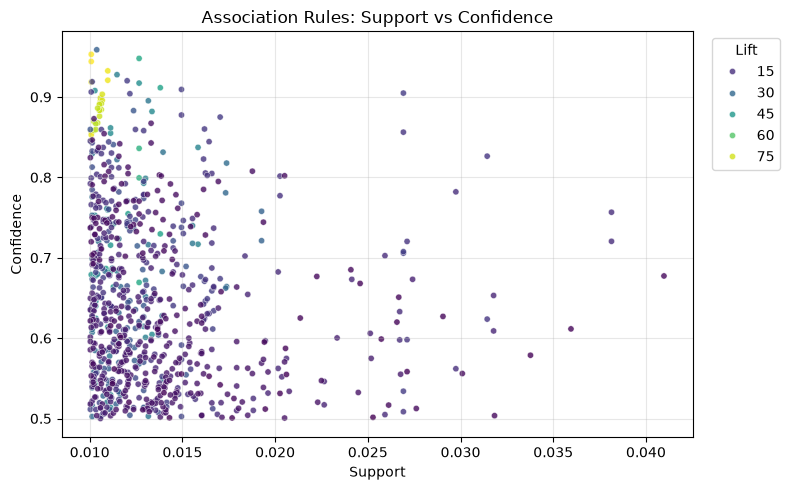

In [21]:
plt.figure(figsize=(8, 5))
sb.scatterplot(data=result, x='support', y='confidence', hue='lift', palette='viridis', s=20, alpha=0.8)
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.grid(alpha=0.3)
plt.legend(title='Lift', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title('Association Rules: Support vs Confidence')
plt.tight_layout()
plt.savefig('scatter.png', dpi=200)
plt.show()

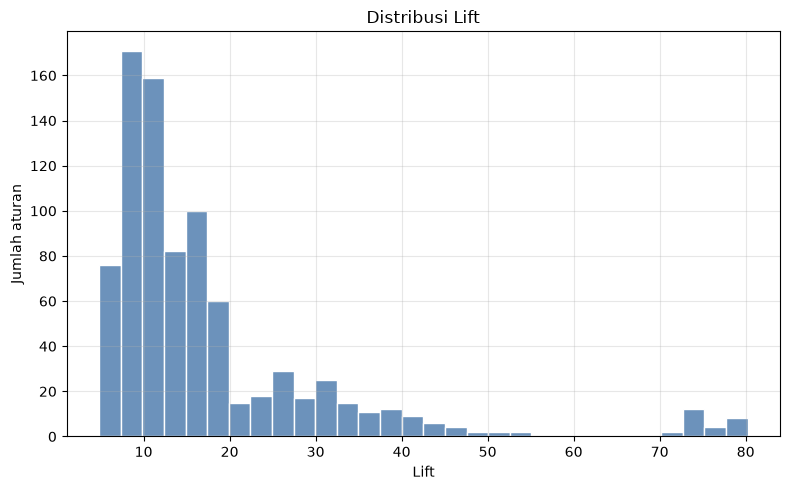

In [22]:
plt.figure(figsize=(8, 5))
sb.histplot(x=result['lift'], bins=30, color='#3b6ea5', edgecolor='white')
plt.xlabel('Lift')
plt.ylabel('Jumlah aturan')
plt.title('Distribusi Lift')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lift.png', dpi=200)
plt.show()

## Interpretasi Tiga Aturan Terbaik (berdasarkan Lift)

Ketiga aturan teratas berasal dari satu itemset yang sama, yaitu {HERB MARKER PARSLEY, HERB MARKER ROSEMARY, HERB MARKER THYME}, dengan
support 0,0101 (sekitar 203 dari 20.136 invoice).

|No|Antecedent|Consequent|Support|Confidence|Lift|
|-|-|-|-|--|-|
|1|Parsley + Rosemary | Thyme | 0,0101 | 0,944 | 80,22 |
|2| Thyme | Parsley + Rosemary | 0,0101 | 0,857 | 80,22 |
|3| Rosemary | Thyme + Parsley | 0,0101 | 0,846 | 79,96 |

**Aturan 1.** Dari seluruh invoice yang memuat Parsley dan Rosemary, 94,4% juga memuat Thyme. Nilai lift 80,22 berarti peluang Thyme dibeli menjadi sekitar 80 kali lebih besar ketika Parsley dan Rosemary sudah ada di keranjang dibandingkan peluang dasarnya (sekitar 1,18% dari semua invoice).

**Aturan 2.** Sebanyak 85,7% pembeli Thyme juga membeli Parsley dan Rosemary sekaligus. Lift yang sama dengan aturan 1 wajar, karena lift bersifat simetris untuk itemset yang sama.

**Aturan 3.** Sebanyak 84,6% pembeli Rosemary juga membeli Thyme dan Parsley.

**Implikasi bisnis.** Ketiga produk penanda tanaman herbal ini hampir selalu dibeli bersamaan, sehingga toko dapat: (1) menjualnya sebagai paket bundlingdengan diskon, (2) menempatkannya berdekatan pada halaman produk atau rak, dan (3) merekomendasikan dua produk lainnya ketika pelanggan menaruh salah satunya ke keranjang.